In [61]:
import pandas as pd
import numpy as np

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import IsolationForest
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split

In [62]:
employee_path = "./data/employee_data.csv"
vendor_path = "./data/vendor_data.csv"
insurance_path = "./data/insurance_data.csv"

employee_df = pd.read_csv(employee_path)
vendor_df = pd.read_csv(vendor_path)
insurance_df = pd.read_csv(insurance_path)

In [63]:

# #employee data
# print("Employee Data:")
# print(employee_df.head())
# # vendor data
# print("\nVendor Data:")
# print(vendor_df.head())
# insurance data
print("\nInsurance Data:")
print(insurance_df.head())



Insurance Data:
         TXN_DATE_TIME TRANSACTION_ID CUSTOMER_ID POLICY_NUMBER POLICY_EFF_DT  \
0  2020-06-01 00:00:00    TXN00000001   A00003822   PLC00008468    2015-06-23   
1  2020-06-01 00:00:00    TXN00000002   A00008149   PLC00009594    2018-04-21   
2  2020-06-01 00:00:00    TXN00000003   A00003172   PLC00007969    2019-10-03   
3  2020-06-01 00:00:00    TXN00000004   A00007572   PLC00009292    2016-11-29   
4  2020-06-01 00:00:00    TXN00000005   A00008173   PLC00000204    2011-12-26   

      LOSS_DT   REPORT_DT INSURANCE_TYPE  PREMIUM_AMOUNT  CLAIM_AMOUNT  ...  \
0  2020-05-16  2020-05-21         Health          157.13          9000  ...   
1  2020-05-13  2020-05-18       Property          141.71         26000  ...   
2  2020-05-21  2020-05-26       Property          157.24         13000  ...   
3  2020-05-14  2020-05-19         Health          172.87         16000  ...   
4  2020-05-17  2020-05-22         Travel           88.53          3000  ...   

  CLAIM_STATUS INCIDE

In [64]:
## merging datasets

merged_df = insurance_df.merge(employee_df, on="AGENT_ID", how="left")
merged_df = merged_df.merge(vendor_df, on="VENDOR_ID", how="left")

print("Merged Dataset Shape:", merged_df.shape)
print("Merged Complete!")

Merged Dataset Shape: (10000, 53)
Merged Complete!


In [65]:
merged_df['INSURANCE_TYPE'] = merged_df['INSURANCE_TYPE'].replace('Health', 'Medicaid')

In [66]:
# 2. Scale the data to 100,000 rows (Large-Scale)
# We repeat the data 10 times
large_scale_df = pd.concat([merged_df] * 10, ignore_index=True)
# 3. Randomize the IDs so they are unique 'Claims'
large_scale_df['TRANSACTION_ID'] = "TXN_L_" + large_scale_df.index.astype(str)
large_scale_df['CLAIM_AMOUNT'] = large_scale_df['CLAIM_AMOUNT'] + np.random.randint(-100, 100, size=len(large_scale_df))

In [67]:
# 6. EXPORT: Save the final file to the DATA folder
output_path = 'data/final_large_scale_medicaid_data.csv'
large_scale_df.to_csv(output_path, index=False)
print(f"Project Data Ready! File exported to: {output_path}")
print(f"Total Records for Scaling Test: {len(large_scale_df)}")

Project Data Ready! File exported to: data/final_large_scale_medicaid_data.csv
Total Records for Scaling Test: 100000


In [68]:
df_final = pd.read_csv("data/final_large_scale_medicaid_data.csv")

print(df_final.head())
print(df_final.info())

         TXN_DATE_TIME TRANSACTION_ID CUSTOMER_ID POLICY_NUMBER POLICY_EFF_DT  \
0  2020-06-01 00:00:00        TXN_L_0   A00003822   PLC00008468    2015-06-23   
1  2020-06-01 00:00:00        TXN_L_1   A00008149   PLC00009594    2018-04-21   
2  2020-06-01 00:00:00        TXN_L_2   A00003172   PLC00007969    2019-10-03   
3  2020-06-01 00:00:00        TXN_L_3   A00007572   PLC00009292    2016-11-29   
4  2020-06-01 00:00:00        TXN_L_4   A00008173   PLC00000204    2011-12-26   

      LOSS_DT   REPORT_DT INSURANCE_TYPE  PREMIUM_AMOUNT  CLAIM_AMOUNT  ...  \
0  2020-05-16  2020-05-21       Medicaid          157.13          8901  ...   
1  2020-05-13  2020-05-18       Property          141.71         26086  ...   
2  2020-05-21  2020-05-26       Property          157.24         12984  ...   
3  2020-05-14  2020-05-19       Medicaid          172.87         15908  ...   
4  2020-05-17  2020-05-22         Travel           88.53          3027  ...   

  STATE_y POSTAL_CODE_y EMP_ROUTING_NU

In [69]:
date_cols = [
    "TXN_DATE_TIME",
    "POLICY_EFF_DT",
    "LOSS_DT",
    "REPORT_DT",
    "DATE_OF_JOINING"
]

for col in date_cols:
    df_final[col] = pd.to_datetime(df_final[col])

In [ ]:
df_final["policy_age_days"] = (df_final["TXN_DATE_TIME"] - df_final ["POLICY_EFF_DT"]).dt.days
df_final["claim_delay_days"] = (df_final["REPORT_DT"] - df_final["LOSS_DT"]).dt.days
df_final["employee_experience_days"] = (df_final["TXN_DATE_TIME"] - df_final["DATE_OF_JOINING"]).dt.days

In [71]:
print(df_final.head())
print(df_final.info())

  TXN_DATE_TIME TRANSACTION_ID CUSTOMER_ID POLICY_NUMBER POLICY_EFF_DT  \
0    2020-06-01        TXN_L_0   A00003822   PLC00008468    2015-06-23   
1    2020-06-01        TXN_L_1   A00008149   PLC00009594    2018-04-21   
2    2020-06-01        TXN_L_2   A00003172   PLC00007969    2019-10-03   
3    2020-06-01        TXN_L_3   A00007572   PLC00009292    2016-11-29   
4    2020-06-01        TXN_L_4   A00008173   PLC00000204    2011-12-26   

     LOSS_DT  REPORT_DT INSURANCE_TYPE  PREMIUM_AMOUNT  CLAIM_AMOUNT  ...  \
0 2020-05-16 2020-05-21       Medicaid          157.13          8901  ...   
1 2020-05-13 2020-05-18       Property          141.71         26086  ...   
2 2020-05-21 2020-05-26       Property          157.24         12984  ...   
3 2020-05-14 2020-05-19       Medicaid          172.87         15908  ...   
4 2020-05-17 2020-05-22         Travel           88.53          3027  ...   

  POSTAL_CODE_y EMP_ROUTING_NUMBER     EMP_ACCT_NUMBER  \
0         37217           35441155

In [72]:
features = ['PREMIUM_AMOUNT', 'CLAIM_AMOUNT', 'policy_age_days', 'claim_delay_days']  # claim_delay_days can be calculated

Detected 1992 potentially fraudulent claims
     PREMIUM_AMOUNT  CLAIM_AMOUNT  policy_age_days  claim_delay_days
10            61.45         91963              429                 5
65            67.55         96011             3393                 2
94            83.23         94971             1027                 1
116           82.01         99967              164                 3
120           56.22         97026             2268                 5


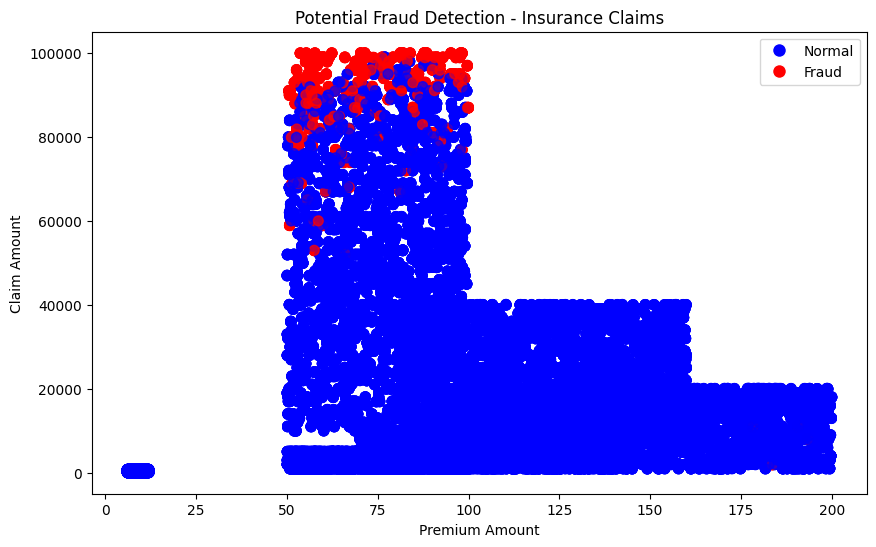

In [74]:
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
import matplotlib.pyplot as plt

if 'claim_delay_days' not in df_final.columns:
    df_final['claim_delay_days'] = (df_final['REPORT_DT'] - df_final['LOSS_DT']).dt.days

X = df_final[features].copy()

# Step 4: Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Step 5: Train Isolation Forest for anomaly detection
iso_forest = IsolationForest(n_estimators=200, contamination=0.02, random_state=42)
iso_forest.fit(X_scaled)

# Step 6: Predict anomalies
df_final['fraud_flag'] = iso_forest.predict(X_scaled)
# Convert -1 to 1 for fraud, 1 to 0 for normal
df_final['fraud_flag'] = df_final['fraud_flag'].apply(lambda x: 1 if x == -1 else 0)

# Step 7: Inspect detected potential frauds
fraud_claims = df_final[df_final['fraud_flag'] == 1]
print(f"Detected {len(fraud_claims)} potentially fraudulent claims")
print(fraud_claims[['PREMIUM_AMOUNT','CLAIM_AMOUNT','policy_age_days','claim_delay_days']].head())
# Map fraud_flag to colors: 1 → red (fraud), 0 → blue (normal)
colors = df_final['fraud_flag'].map({0: 'blue', 1: 'red'})

plt.figure(figsize=(10,6))
plt.scatter(df_final['PREMIUM_AMOUNT'], df_final['CLAIM_AMOUNT'], c=colors, s=50, alpha=0.7)
plt.xlabel("Premium Amount")
plt.ylabel("Claim Amount")
plt.title("Potential Fraud Detection - Insurance Claims")
plt.legend(handles=[
    plt.Line2D([0], [0], marker='o', color='w', label='Normal', markerfacecolor='blue', markersize=10),
    plt.Line2D([0], [0], marker='o', color='w', label='Fraud', markerfacecolor='red', markersize=10)
])
plt.show()